# CSE475 — Task 1: Exploratory Data Analysis
## TON_IoT (network) · Track 1: Graph Neural Network

**Group:** 07 · Section 01
**Dataset:** TON_IoT network dataset, `train_test_network.csv` (UNSW Canberra)
**Track:** 1 — GNN on network-flow data: hosts are nodes, flows are edges
**File:** `code/task1/Group07_TONIoT_task1_eda.ipynb`

---

### Why this dataset

Our first dataset, UNSW-NB15, had a majority-to-minority ratio of 11,322 : 1
(Normal 600,079 vs Worms 53). On faculty advice we moved to TON_IoT, which the
brief lists for Track 1, keeps source and destination IP columns for building a
host graph, and is far less imbalanced.

### What this notebook delivers

| § | Content |
|---|---|
| A | Dataset summary table |
| B | Descriptive statistics |
| C | Data quality (including Zeek `-` placeholders) |
| D | Class balance |
| E | Feature distributions |
| F | Correlation and redundancy |
| G | PCA / t-SNE / UMAP projection |
| H | Interactive plots |
| P1 | Host graph — does a real graph exist? |
| P2 | Identifier and timestamp leakage |
| P3 | Label-quality check (known ToN-IoT labelling issues) |
| P4 | Three-way host-disjoint split |
| S | Findings summary, exported to `findings.json` |

Every figure has a title, axis labels and a printed **Reading:** line.

## 0 · Setup

Imports, fixed random seed, and plot defaults. Runs on **CPU** — no GPU needed.

In [7]:
import os, sys, json, warnings, random, ipaddress
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.autolayout": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10, "legend.frameon": False,
})
sns.set_palette("colorblind")

OUT = Path("figures"); OUT.mkdir(exist_ok=True)
TBL = Path("tables");  TBL.mkdir(exist_ok=True)
FINDINGS = {}          # every key number lands here, exported at the end

def save(fig, name):
    p = OUT / f"{name}.png"; fig.savefig(p, bbox_inches="tight"); return p
def dump(df, name):
    p = TBL / f"{name}.csv"; df.to_csv(p, index=True); return p
def reading(text):
    print("\nReading: " + text)

for m in (pd, np, matplotlib, sns):
    print(f"{m.__name__:<11}", m.__version__)

pandas      2.3.3
numpy       2.1.3
matplotlib  3.10.0
seaborn     0.13.2


## 0.1 · Locate the dataset

Attach the dataset first: **+ Add Input → Datasets** → search `TON_IoT` → add a
dataset containing `train_test_network.csv`. This cell lists every CSV it finds
and picks the TON_IoT network file automatically by checking its columns.

In [8]:
SEARCH_ROOTS = ["/kaggle/input", ".", "data"]
REQUIRED = {"src_ip", "dst_ip", "type"}

def clean_cols(cols):
        return [str(c).replace("\ufeff", "").replace("ï»¿", "").strip().lower() for c in cols]

cands = []
for root in SEARCH_ROOTS:
    if not os.path.isdir(root):
        continue
    for d, _, files in os.walk(root):
        for f in files:
            if not f.lower().endswith(".csv"):
                continue
            p = Path(d) / f
            try:
                cols = clean_cols(pd.read_csv(p, nrows=0, encoding="latin-1").columns)
            except Exception as e:
                print("could not read", f, e); continue
            cands.append({"file": f, "path": str(p),
                          "size_MB": round(p.stat().st_size / 1e6, 1),
                          "is_network": REQUIRED <= set(cols), "cols": cols})

inv = pd.DataFrame(cands)
print(inv[["file", "size_MB", "is_network"]].to_string(index=False))

net = inv[inv["is_network"]]
if net.empty:
    print("\nColumns found in each file:")
    for _, r in inv.iterrows():
        print(r["file"], "->", r["cols"])
    raise SystemExit("Send these column names to Claude.")

pref = net[net["file"].str.lower().str.contains("train_test")]
DATA_PATH = (pref if len(pref) else net).iloc[0]["path"]
print("\nUsing:", DATA_PATH)

                  file  size_MB  is_network
train_test_network.csv     29.9        True

Using: /kaggle/input/datasets/afnanbd/train-test-network-csv/train_test_network.csv


## 0.2 · Load and normalise

TON_IoT was produced with the Zeek (Bro) network monitor, which writes `-` when a
field does not apply (for example, `dns_query` on a non-DNS flow). We count those
placeholders separately from true missing values, then convert numeric-looking
columns to numbers.

In [9]:
MAX_ROWS = None   # train_test_network.csv is ~461k rows and fits in memory

def read_any(p, **kw):
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(p, encoding=enc, low_memory=False, **kw)
        except UnicodeDecodeError:
            continue
    return pd.read_csv(p, encoding="latin-1", encoding_errors="replace", low_memory=False, **kw)

raw = read_any(DATA_PATH, nrows=MAX_ROWS)
raw.columns = raw.columns.str.strip()
print("shape:", raw.shape)

# Count Zeek "-" placeholders BEFORE converting them.
dash = (raw.astype(str).apply(lambda s: s.str.strip()) == "-").sum()
dash = dash[dash > 0].sort_values(ascending=False)

df = raw.replace({"-": np.nan, "": np.nan})

# Targets
df["type"] = df["type"].astype(str).str.strip().str.lower()
if "label" in df.columns:
    df["label"] = pd.to_numeric(df["label"], errors="coerce").astype("Int64")
else:
    df["label"] = (df["type"] != "normal").astype(int)

# Convert numeric-looking columns
for c in df.columns:
    if c in ("type", "src_ip", "dst_ip") or pd.api.types.is_numeric_dtype(df[c]):
        continue
    conv = pd.to_numeric(df[c], errors="coerce")
    if conv.notna().sum() >= 0.95 * df[c].notna().sum() and df[c].notna().any():
        df[c] = conv

print("classes:", sorted(df["type"].unique()))
FINDINGS["rows"] = int(len(df)); FINDINGS["columns"] = int(df.shape[1])

shape: (211043, 44)
classes: ['backdoor', 'ddos', 'dos', 'injection', 'mitm', 'normal', 'password', 'ransomware', 'scanning', 'xss']


In [10]:
# Column roles
TARGET_BIN, TARGET_MULTI = "label", "type"
ID_LIKE = [c for c in ["ts", "src_ip", "src_port", "dst_ip", "dst_port"] if c in df.columns]

num_cols = [c for c in df.select_dtypes(include=[np.number]).columns
            if c not in ID_LIKE + [TARGET_BIN]]
obj_cols = [c for c in df.columns if c not in num_cols + ID_LIKE + [TARGET_BIN, TARGET_MULTI]]

# Free-text fields (very many distinct values) cannot be one-hot encoded and can
# memorise individual sessions; flag them separately.
TEXT_LIKE = [c for c in obj_cols if df[c].nunique() > 100]
FEAT_CAT  = [c for c in obj_cols if c not in TEXT_LIKE]
FEAT_NUM  = num_cols

print(f"numeric features    : {len(FEAT_NUM)} -> {FEAT_NUM}")
print(f"categorical features: {len(FEAT_CAT)} -> {FEAT_CAT}")
print(f"free-text fields    : {len(TEXT_LIKE)} -> {TEXT_LIKE}")
print(f"identifier-like     : {ID_LIKE}  (graph structure only, never features)")
FINDINGS.update(n_numeric=len(FEAT_NUM), n_categorical=len(FEAT_CAT),
                n_text=len(TEXT_LIKE), id_like=ID_LIKE, text_like=TEXT_LIKE)

numeric features    : 17 -> ['duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'http_trans_depth', 'http_version', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'weird_addl']
categorical features: 20 -> ['proto', 'service', 'conn_state', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_method', 'http_uri', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_notice']
free-text fields    : 1 -> ['dns_query']
identifier-like     : ['src_ip', 'src_port', 'dst_ip', 'dst_port']  (graph structure only, never features)


## A · Dataset summary table

In [11]:
hosts = pd.concat([df["src_ip"], df["dst_ip"]]).nunique()
A = pd.DataFrame({
    "Value": {
        "Dataset": "TON_IoT — network (train_test_network)",
        "Source": "Cyber Range & IoT Labs, UNSW Canberra (Moustafa et al.)",
        "Application area": "Network intrusion detection for IoT/IIoT",
        "Monitoring tool": "Zeek (Bro) connection logs",
        "Rows": f"{len(df):,}",
        "Columns": df.shape[1],
        "Numeric / categorical / free-text features": f"{len(FEAT_NUM)} / {len(FEAT_CAT)} / {len(TEXT_LIKE)}",
        "Identifier columns": ", ".join(ID_LIKE),
        "Problem type": "Binary (label) + multiclass (type)",
        "Classes (type)": df[TARGET_MULTI].nunique(),
        "Distinct hosts (IPs)": f"{hosts:,}",
        "Class balance": f"{(1-df[TARGET_BIN].astype(float).mean())*100:.1f}% normal / {df[TARGET_BIN].astype(float).mean()*100:.1f}% attack",
        "True missing cells": f"{int(raw.isna().sum().sum()):,}",
        "Zeek '-' placeholder cells": f"{int(dash.sum()):,}",
        "Duplicate rows": f"{int(df.duplicated().sum()):,}",
    }})
dump(A, "A_dataset_summary"); FINDINGS["hosts"] = int(hosts)
A

,Value
Dataset,TON_IoT — network (train_test_network)
Source,"Cyber Range & IoT Labs, UNSW Canberra (Moustaf..."
Application area,Network intrusion detection for IoT/IIoT
Monitoring tool,Zeek (Bro) connection logs
Rows,"211,043"
Columns,44
Numeric / categorical / free-text features,17 / 20 / 1
Identifier columns,"src_ip, src_port, dst_ip, dst_port"
Problem type,Binary (label) + multiclass (type)
Classes (type),10


In [12]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_or_dash_%": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
    "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
})
schema["role"] = ["identifier" if c in ID_LIKE else "target" if c in (TARGET_BIN, TARGET_MULTI)
                  else "free-text" if c in TEXT_LIKE else "categorical" if c in FEAT_CAT
                  else "numeric" for c in df.columns]
dump(schema, "A_column_schema")
schema

,dtype,missing_or_dash_%,n_unique,example,role
src_ip,object,0.00,51,192.168.1.37,identifier
src_port,int64,0.00,26628,4444,identifier
dst_ip,object,0.00,753,192.168.1.193,identifier
dst_port,int64,0.00,2039,49178,identifier
proto,object,0.00,3,tcp,categorical
service,object,62.56,8,smb;gssapi,categorical
duration,float64,0.00,68570,290.371539,numeric
src_bytes,int64,0.00,2199,101568,numeric
dst_bytes,int64,0.00,2338,2592,numeric
conn_state,object,0.00,13,OTH,categorical


## B · Descriptive statistics

Mean, median, spread, quartiles, skewness, kurtosis and IQR outliers for each
numeric feature.

In [13]:
d = df[FEAT_NUM]
q1, q3 = d.quantile(.25), d.quantile(.75); iqr = q3 - q1
B = pd.DataFrame({
    "mean": d.mean(), "median": d.median(), "std": d.std(), "min": d.min(),
    "q25": q1, "q75": q3, "max": d.max(), "skew": d.skew(), "kurtosis": d.kurtosis(),
    "outliers_%": (((d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)).mean() * 100),
}).round(3)
dump(B, "B_descriptive_statistics")
n_skew = int((B["skew"].abs() > 2).sum())
print(f"|skew| > 2 : {n_skew} of {len(B)}")
print(f"kurtosis > 10 : {int((B['kurtosis'] > 10).sum())} of {len(B)}")
FINDINGS.update(n_skewed=n_skew, n_numeric_checked=len(B),
                most_skewed=B["skew"].abs().idxmax(), max_skew=float(B["skew"].abs().max()))
reading("Byte and packet counts are heavily right-skewed: most flows are tiny and a "
        "few are enormous. We will apply log1p and standardise, fitted on training data only.")
B

|skew| > 2 : 16 of 17
kurtosis > 10 : 16 of 17

Reading: Byte and packet counts are heavily right-skewed: most flows are tiny and a few are enormous. We will apply log1p and standardise, fitted on training data only.


,mean,median,std,min,q25,q75,max,skew,kurtosis,outliers_%
duration,7.701,0.0,5.641420e+02,0.0,0.0,0.054,9.351693e+04,155.906,25102.642,22.588
src_bytes,258113.564,0.0,1.709490e+07,0.0,0.0,130.000,3.890855e+09,101.369,15634.817,5.888
dst_bytes,258804.572,0.0,1.802563e+07,0.0,0.0,89.000,3.913853e+09,113.945,18477.091,20.450
missed_bytes,34432.344,0.0,5.261621e+06,0.0,0.0,0.000,1.854527e+09,252.712,79078.549,1.395
src_pkts,9.595,1.0,9.177900e+01,0.0,1.0,4.000,2.462300e+04,134.754,28778.511,7.303
src_ip_bytes,776.082,82.0,2.229703e+04,0.0,48.0,415.000,6.522626e+06,165.657,39140.303,10.246
dst_pkts,3.847,1.0,3.307060e+02,0.0,0.0,2.000,1.219420e+05,291.125,96736.021,11.501
dst_ip_bytes,1584.687,40.0,1.901795e+05,0.0,0.0,134.000,8.639552e+07,444.671,201809.850,20.582
dns_qclass,227.631,0.0,2.720714e+03,0.0,0.0,0.000,3.276900e+04,11.877,139.067,16.474
dns_qtype,3.611,0.0,2.379800e+01,0.0,0.0,0.000,2.550000e+02,9.867,100.737,16.474


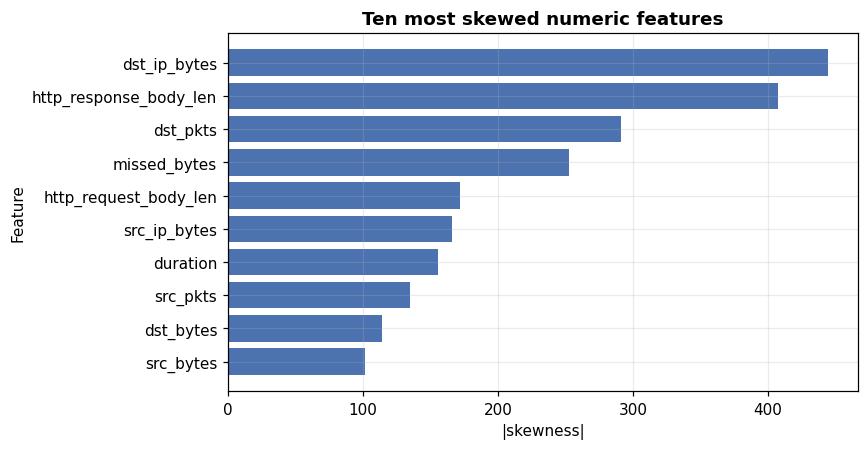


Reading: 'dst_ip_bytes' is the most skewed (|skew| = 444.7).


In [14]:
top = B["skew"].abs().sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index[::-1], top.values[::-1], color="#4C72B0")
ax.set_title("Ten most skewed numeric features"); ax.set_xlabel("|skewness|"); ax.set_ylabel("Feature")
save(fig, "B_top_skew"); plt.show()
reading(f"'{top.index[0]}' is the most skewed (|skew| = {top.iloc[0]:.1f}).")

## C · Data quality

1. True missing values and Zeek `-` placeholders
2. Duplicate rows, and duplicates with **conflicting labels**
3. Near-constant features
4. Highly correlated pairs

In [15]:
print("C1 · '-' placeholders per column (field not applicable to that flow)")
C1 = pd.DataFrame({"dash_cells": dash, "dash_%": (dash / len(df) * 100).round(2)})
print(C1.to_string()); dump(C1, "C1_placeholders")
FINDINGS["placeholder_cols"] = C1.head(10)["dash_%"].round(1).to_dict()
reading("A '-' means the field does not apply (e.g. HTTP fields on a DNS flow), not that "
        "data was lost. We keep that information as an explicit 'not applicable' category "
        "or indicator rather than imputing a fake number.")

C1 · '-' placeholders per column (field not applicable to that flow)
                      dash_cells  dash_%
ssl_subject               211032   99.99
ssl_issuer                211032   99.99
http_orig_mime_types      211027   99.99
weird_addl                210886   99.93
http_resp_mime_types      210839   99.90
http_uri                  210756   99.86
http_method               210756   99.86
http_user_agent           210756   99.86
http_version              210745   99.86
http_trans_depth          210740   99.86
weird_name                210687   99.83
weird_notice              210687   99.83
ssl_version               210642   99.81
ssl_cipher                210642   99.81
ssl_resumed               210642   99.81
ssl_established           210642   99.81
dns_query                 176198   83.49
dns_AA                    176030   83.41
dns_RD                    176030   83.41
dns_rejected              176030   83.41
dns_RA                    176030   83.41
service                   132

In [16]:
feat_cols = [c for c in df.columns if c not in ID_LIKE + [TARGET_BIN, TARGET_MULTI]]
n_dup = int(df.duplicated().sum())
n_dup_feat = int(df[feat_cols].duplicated().sum())

# Same features, different attack type => label noise.
g = df.groupby(feat_cols, dropna=False)[TARGET_MULTI].nunique()
conflict_groups = int((g > 1).sum())
conflict_rows = int(df.set_index(feat_cols).index.isin(g[g > 1].index).sum()) if conflict_groups else 0

print(f"Exact duplicate rows              : {n_dup:,} ({n_dup/len(df)*100:.2f}%)")
print(f"Duplicates ignoring identifiers   : {n_dup_feat:,} ({n_dup_feat/len(df)*100:.2f}%)")
print(f"Feature groups with >1 attack type: {conflict_groups:,} (covering {conflict_rows:,} rows)")
FINDINGS.update(dup_rows=n_dup, dup_feat_rows=n_dup_feat,
                conflict_groups=conflict_groups, conflict_rows=conflict_rows)
reading("Identical feature vectors carrying different labels cannot be separated by any "
        "model; they cap achievable accuracy. Exact duplicates are removed before splitting.")

Exact duplicate rows              : 20,569 (9.75%)
Duplicates ignoring identifiers   : 117,317 (55.59%)
Feature groups with >1 attack type: 162 (covering 22,643 rows)

Reading: Identical feature vectors carrying different labels cannot be separated by any model; they cap achievable accuracy. Exact duplicates are removed before splitting.


In [17]:
rows = []
for c in FEAT_NUM + FEAT_CAT:
    vc = df[c].value_counts(normalize=True, dropna=False)
    if len(vc) and vc.iloc[0] >= 0.99:
        rows.append({"feature": c, "top_value": vc.index[0], "share_%": round(vc.iloc[0] * 100, 2)})
C3 = pd.DataFrame(rows); dump(C3, "C3_near_constant")
print(C3.to_string(index=False) if len(C3) else "None at 99%.")
FINDINGS["near_constant"] = C3["feature"].tolist() if len(C3) else []

               feature  top_value  share_%
      http_trans_depth        NaN    99.86
          http_version        NaN    99.86
 http_request_body_len        0.0    99.99
http_response_body_len        0.0    99.87
      http_status_code        0.0    99.86
            weird_addl        NaN    99.93
           ssl_version        NaN    99.81
            ssl_cipher        NaN    99.81
           ssl_resumed        NaN    99.81
       ssl_established        NaN    99.81
           ssl_subject        NaN    99.99
            ssl_issuer        NaN    99.99
           http_method        NaN    99.86
              http_uri        NaN    99.86
       http_user_agent        NaN    99.86
  http_orig_mime_types        NaN    99.99
  http_resp_mime_types        NaN    99.90
            weird_name        NaN    99.83
          weird_notice        NaN    99.83


In [18]:
cm = df[FEAT_NUM].corr().abs()
up = cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool))
pairs = up.stack().loc[lambda s: s >= 0.95].sort_values(ascending=False).reset_index()
pairs.columns = ["feature_1", "feature_2", "abs_corr"]
dump(pairs, "C4_correlated_pairs")
print(pairs.round(4).to_string(index=False) if len(pairs) else "No pairs above 0.95.")
FINDINGS["corr_pairs"] = pairs.round(3).values.tolist()

No pairs above 0.95.


## D · Class balance

In [19]:
D = df[TARGET_MULTI].value_counts().to_frame("count")
D["share_%"] = (D["count"] / len(df) * 100).round(3)
D["ratio_to_smallest"] = (D["count"] / D["count"].min()).round(1)
dump(D, "D_class_balance"); print(D.to_string())
ratio = D["count"].max() / D["count"].min()
maj = D["count"].max() / len(df)
print(f"\nMajority-to-minority ratio: {ratio:,.1f} : 1")
print(f"Attack share: {df[TARGET_BIN].mean()*100:.2f}%")
print(f"Majority-class baseline: accuracy {maj*100:.2f}%, macro-F1 ~{(2*maj/(1+maj))/len(D)*100:.1f}%")
FINDINGS.update(class_counts=D["count"].to_dict(), imbalance_ratio=float(ratio),
                attack_share=float(df[TARGET_BIN].mean()), majority_acc=float(maj),
                majority_macro_f1=float((2*maj/(1+maj))/len(D)))

            count  share_%  ratio_to_smallest
type                                         
normal      50000   23.692               47.9
backdoor    20000    9.477               19.2
ddos        20000    9.477               19.2
dos         20000    9.477               19.2
injection   20000    9.477               19.2
password    20000    9.477               19.2
scanning    20000    9.477               19.2
ransomware  20000    9.477               19.2
xss         20000    9.477               19.2
mitm         1043    0.494                1.0

Majority-to-minority ratio: 47.9 : 1
Attack share: 76.31%
Majority-class baseline: accuracy 23.69%, macro-F1 ~3.8%


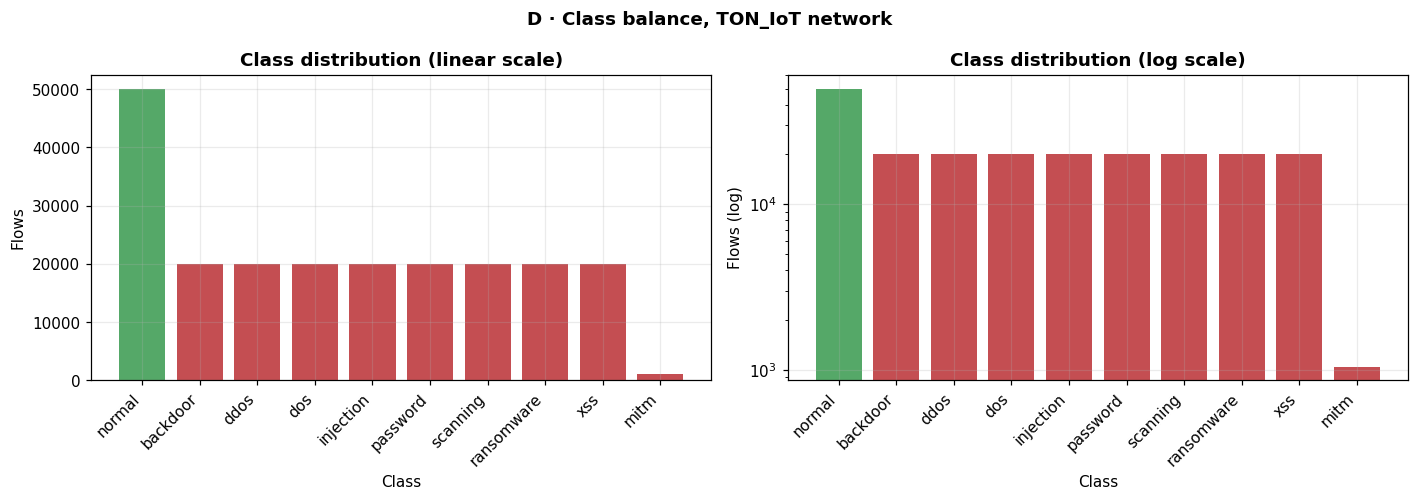


Reading: Worst ratio 48:1, versus 11,322:1 in UNSW-NB15. Most attack classes are equal-sized; the smallest class needs class-weighted loss.


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
colors = ["#55A868" if c == "normal" else "#C44E52" for c in D.index]
for ax, log in zip(axes, (False, True)):
    ax.bar(range(len(D)), D["count"], color=colors)
    ax.set_xticks(range(len(D))); ax.set_xticklabels(D.index, rotation=45, ha="right")
    ax.set_xlabel("Class"); ax.set_ylabel("Flows" + (" (log)" if log else ""))
    if log: ax.set_yscale("log")
    ax.set_title("Class distribution (" + ("log" if log else "linear") + " scale)")
fig.suptitle("D · Class balance, TON_IoT network", fontweight="bold")
save(fig, "D_class_balance"); plt.show()
reading(f"Worst ratio {ratio:,.0f}:1, versus 11,322:1 in UNSW-NB15. Most attack classes are "
        "equal-sized; the smallest class needs class-weighted loss.")

## E · Feature distributions

Features ranked by ANOVA F against the attack type; the top six are plotted.

In [21]:
from sklearn.feature_selection import f_classif
Xs = df[FEAT_NUM].replace([np.inf, -np.inf], np.nan)
Xs = Xs.fillna(Xs.median()).fillna(0.0)
y_multi = df[TARGET_MULTI]
F, p = f_classif(Xs, y_multi)
rank = pd.DataFrame({"feature": FEAT_NUM, "F": F}).sort_values("F", ascending=False).reset_index(drop=True)
dump(rank, "E_feature_rank"); print(rank.head(12).to_string(index=False))
TOPK = rank["feature"].head(6).tolist()
FINDINGS["top_features"] = TOPK

         feature           F
       dns_rcode 3369.246016
       dns_qtype 1715.574697
      dns_qclass  540.554742
        src_pkts  337.336076
    src_ip_bytes   72.027042
http_status_code   60.094949
       src_bytes   38.366348
       dst_bytes   38.209304
    http_version   34.737942
        duration    8.962171
http_trans_depth    8.464109
    missed_bytes    8.360692


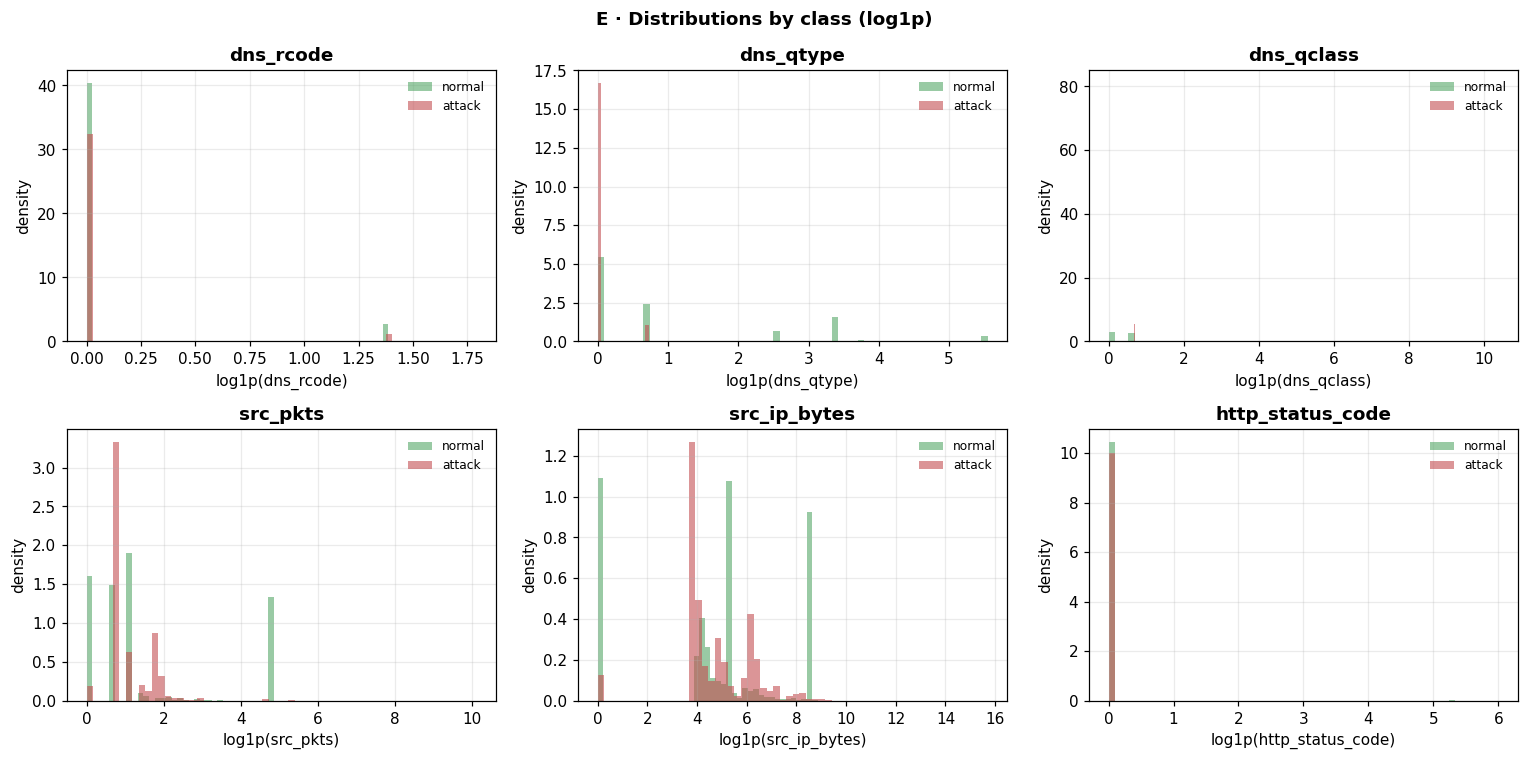


Reading: Where the curves separate, a flat model can tell normal from attack on that feature alone.


In [22]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), TOPK):
    for lab, col, nm in [(0, "#55A868", "normal"), (1, "#C44E52", "attack")]:
        v = df.loc[df[TARGET_BIN] == lab, c].dropna()
        ax.hist(np.log1p(v.clip(lower=0)), bins=60, alpha=.6, density=True, color=col, label=nm)
    ax.set_title(c); ax.set_xlabel(f"log1p({c})"); ax.set_ylabel("density"); ax.legend(fontsize=8)
fig.suptitle("E · Distributions by class (log1p)", fontweight="bold")
save(fig, "E_histograms"); plt.show()
reading("Where the curves separate, a flat model can tell normal from attack on that feature alone.")

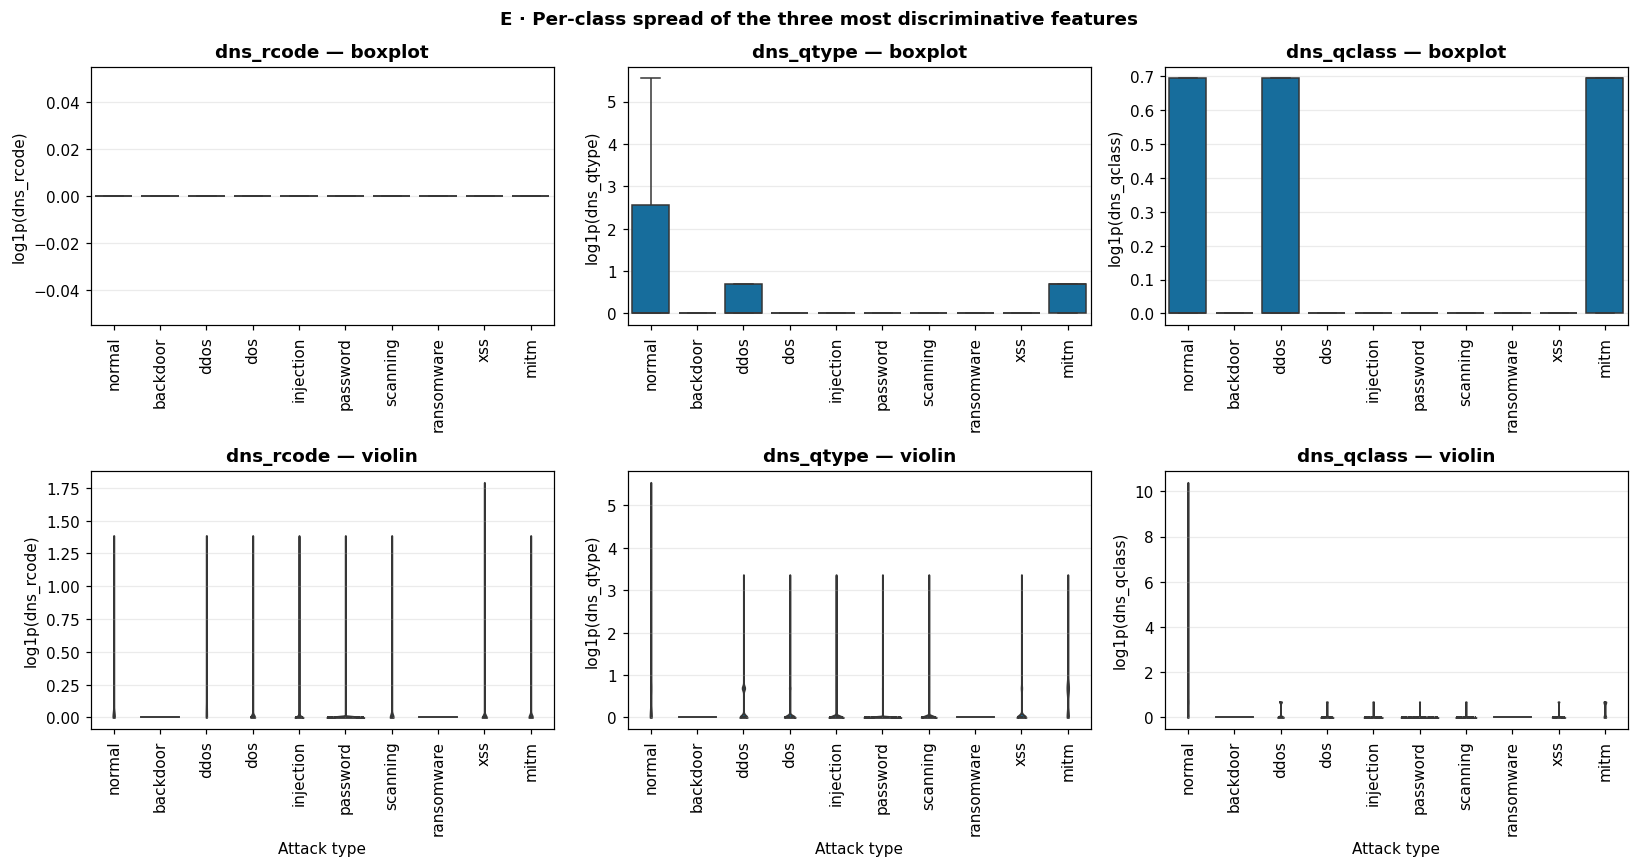


Reading: Classes whose boxes sit at the same level on every feature are the ones the confusion matrix will confuse.


In [23]:
order = D.index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, c in enumerate(TOPK[:3]):
    t = pd.DataFrame({"type": df[TARGET_MULTI], "v": np.log1p(df[c].clip(lower=0))}).dropna()
    sns.boxplot(data=t, x="type", y="v", order=order, ax=axes[0, j], showfliers=False)
    sns.violinplot(data=t, x="type", y="v", order=order, ax=axes[1, j], cut=0, inner="quartile")
    for r in (0, 1):
        axes[r, j].set_ylabel(f"log1p({c})"); axes[r, j].tick_params(axis="x", rotation=90)
    axes[0, j].set_title(f"{c} — boxplot"); axes[1, j].set_title(f"{c} — violin")
    axes[0, j].set_xlabel(""); axes[1, j].set_xlabel("Attack type")
fig.suptitle("E · Per-class spread of the three most discriminative features", fontweight="bold")
save(fig, "E_box_violin"); plt.show()
reading("Classes whose boxes sit at the same level on every feature are the ones the "
        "confusion matrix will confuse.")

## F · Correlation and redundancy

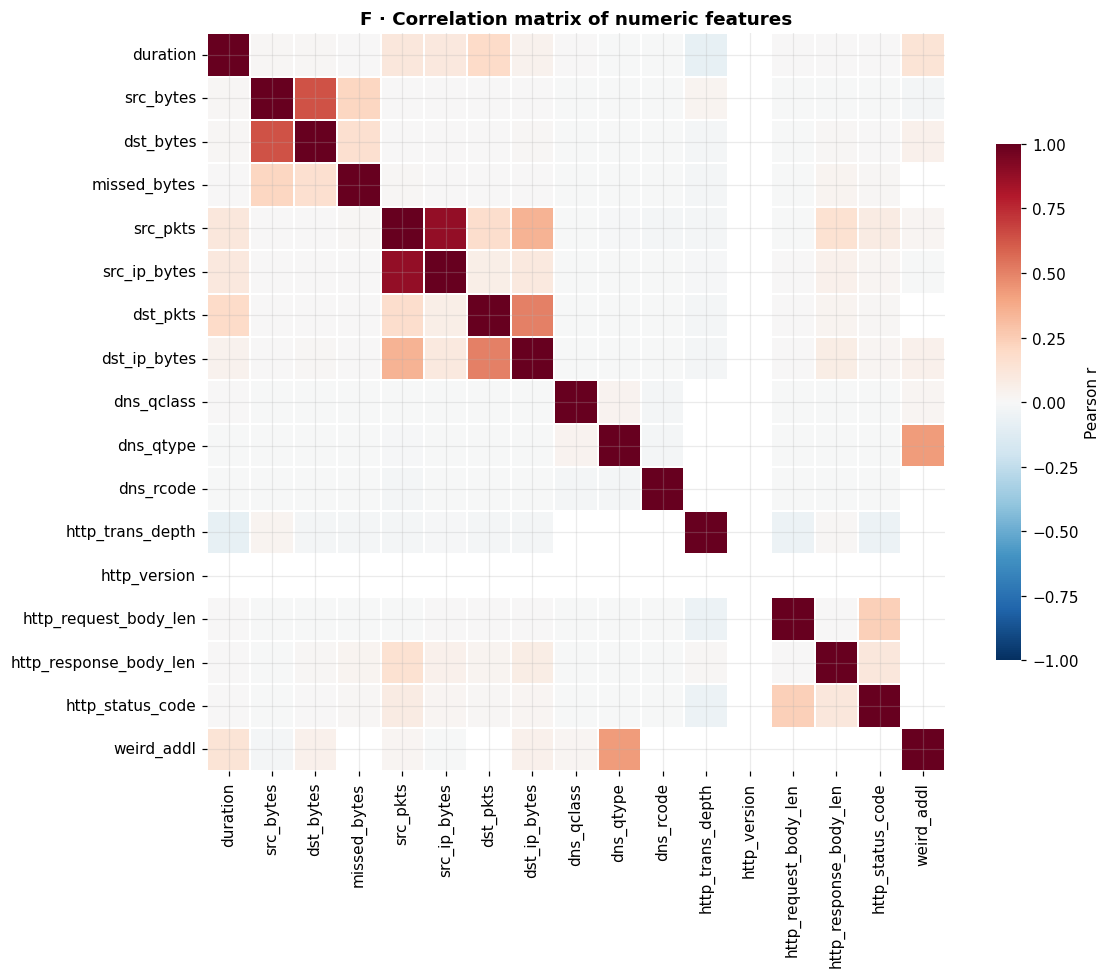


Reading: Byte and packet counters in the same direction move together (e.g. src_bytes / src_ip_bytes / src_pkts). One of each highly correlated pair is dropped before SHAP.


In [24]:
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(df[FEAT_NUM].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            linewidths=.3, cbar_kws={"shrink": .7, "label": "Pearson r"}, ax=ax)
ax.set_title("F · Correlation matrix of numeric features", fontweight="bold")
save(fig, "F_correlation_heatmap"); plt.show()
reading("Byte and packet counters in the same direction move together (e.g. src_bytes / "
        "src_ip_bytes / src_pkts). One of each highly correlated pair is dropped before SHAP.")

## G · Low-dimensional projection

Stratified subsample for t-SNE/UMAP so every class, including the smallest, is shown.

subsample: (6000, 17)


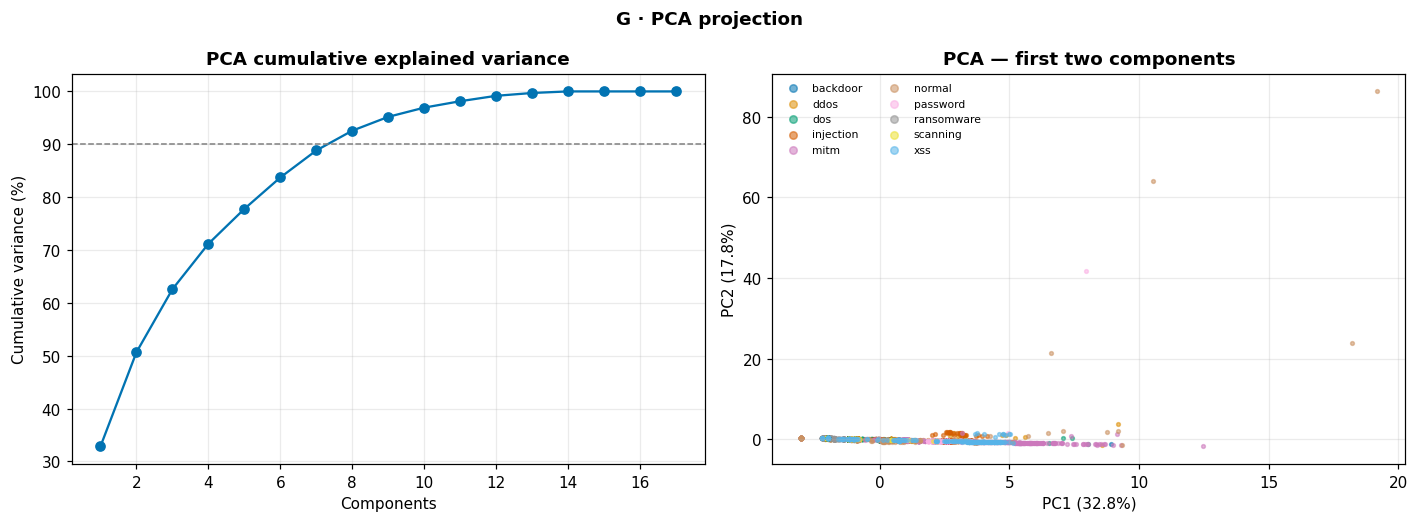


Reading: 8 components explain 90% of the variance.


In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

per = 600
idx = (df.groupby(TARGET_MULTI, group_keys=False)
         .apply(lambda g: g.sample(min(len(g), per), random_state=SEED)).index)
Xz = StandardScaler().fit_transform(np.log1p(Xs.loc[idx].clip(lower=0)))
yp = y_multi.loc[idx]
print("subsample:", Xz.shape)

pca = PCA(n_components=min(20, Xz.shape[1]), random_state=SEED)
Zp = pca.fit_transform(Xz); ev = pca.explained_variance_ratio_
k90 = int(np.argmax(np.cumsum(ev) >= .90) + 1) if np.cumsum(ev)[-1] >= .90 else len(ev)
FINDINGS.update(pca_k90=k90, pc1=float(ev[0]), pc2=float(ev[1]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(range(1, len(ev) + 1), np.cumsum(ev) * 100, "o-")
axes[0].axhline(90, ls="--", c="grey", lw=1)
axes[0].set_title("PCA cumulative explained variance")
axes[0].set_xlabel("Components"); axes[0].set_ylabel("Cumulative variance (%)")
for c in yp.value_counts().index:
    m = (yp == c).values
    axes[1].scatter(Zp[m, 0], Zp[m, 1], s=6, alpha=.55, label=c)
axes[1].set_title("PCA — first two components")
axes[1].set_xlabel(f"PC1 ({ev[0]*100:.1f}%)"); axes[1].set_ylabel(f"PC2 ({ev[1]*100:.1f}%)")
axes[1].legend(fontsize=7, markerscale=2, ncol=2)
fig.suptitle("G · PCA projection", fontweight="bold")
save(fig, "G_pca"); plt.show()
reading(f"{k90} components explain 90% of the variance.")

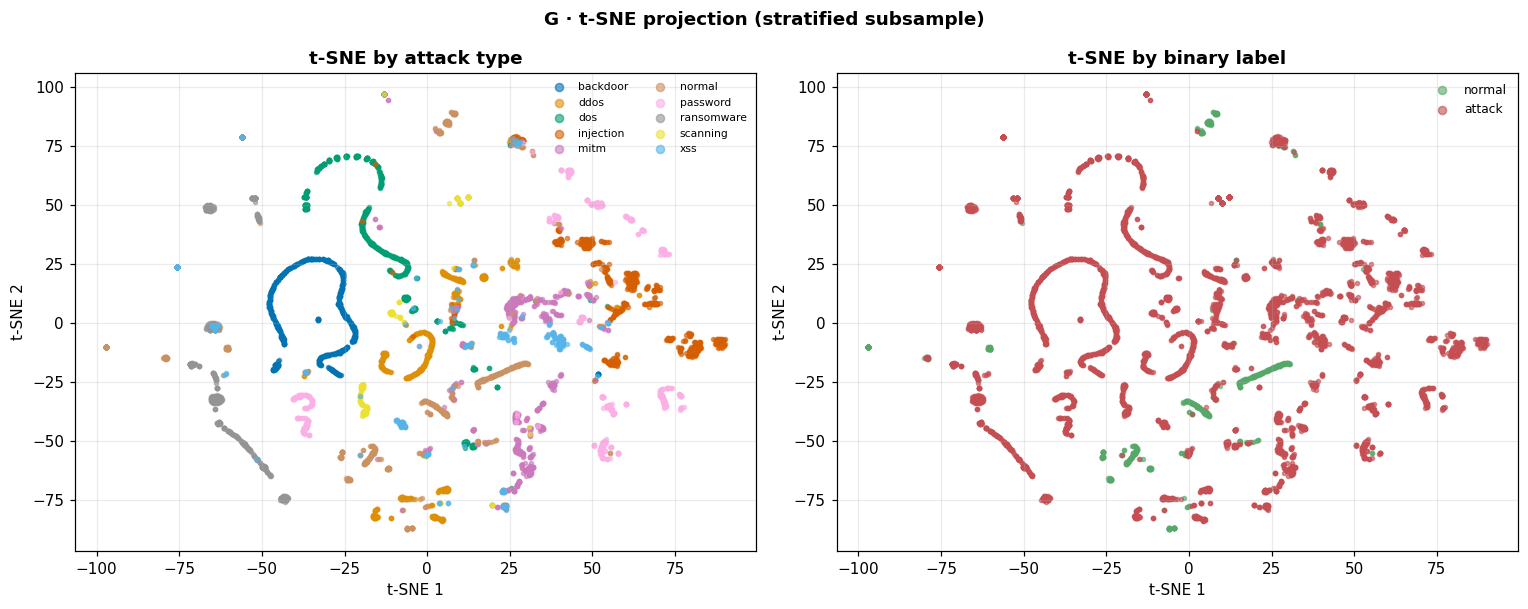


Reading: Separate clusters = easy classes; mixed clusters = classes flow features alone confuse.


In [26]:
Zt = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
          random_state=SEED).fit_transform(Zp)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for c in yp.value_counts().index:
    m = (yp == c).values
    axes[0].scatter(Zt[m, 0], Zt[m, 1], s=7, alpha=.6, label=c)
axes[0].legend(fontsize=7, markerscale=2, ncol=2); axes[0].set_title("t-SNE by attack type")
yb = df[TARGET_BIN].loc[idx].values
for lab, col, nm in [(0, "#55A868", "normal"), (1, "#C44E52", "attack")]:
    m = yb == lab; axes[1].scatter(Zt[m, 0], Zt[m, 1], s=7, alpha=.6, c=col, label=nm)
axes[1].legend(fontsize=8, markerscale=2); axes[1].set_title("t-SNE by binary label")
for a in axes: a.set_xlabel("t-SNE 1"); a.set_ylabel("t-SNE 2")
fig.suptitle("G · t-SNE projection (stratified subsample)", fontweight="bold")
save(fig, "G_tsne"); plt.show()
reading("Separate clusters = easy classes; mixed clusters = classes flow features alone confuse.")

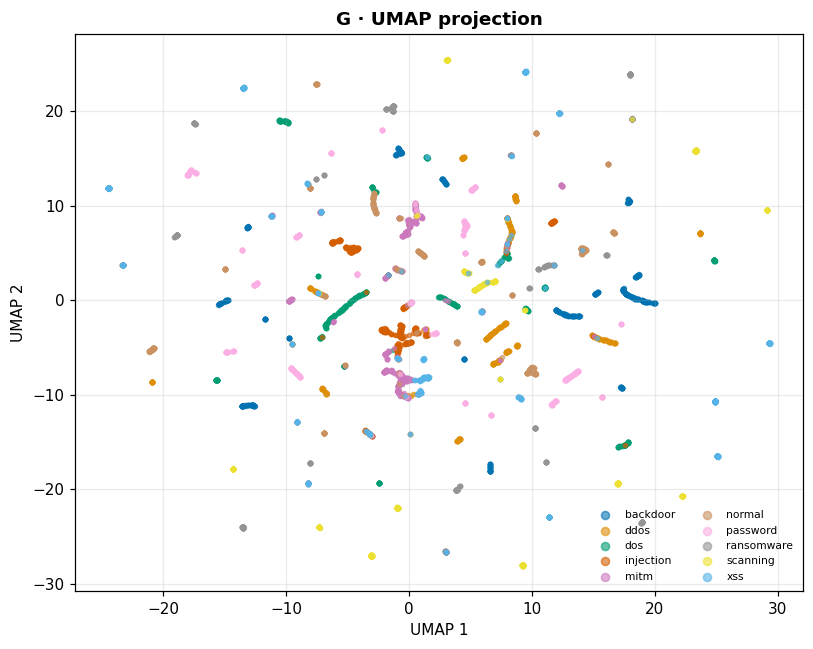

In [27]:
try:
    import umap
    Zu = umap.UMAP(n_neighbors=15, min_dist=.1, random_state=SEED).fit_transform(Xz)
    fig, ax = plt.subplots(figsize=(7.5, 6))
    for c in yp.value_counts().index:
        m = (yp == c).values; ax.scatter(Zu[m, 0], Zu[m, 1], s=7, alpha=.6, label=c)
    ax.set_title("G · UMAP projection", fontweight="bold")
    ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2"); ax.legend(fontsize=7, markerscale=2, ncol=2)
    save(fig, "G_umap"); plt.show()
except ImportError:
    print("umap-learn not installed — skipped (PCA and t-SNE satisfy §G).")

## H · Interactive plots

In [28]:
import plotly.express as px, plotly.io as pio
try: pio.renderers.default = "notebook_connected"
except Exception: pass

Dp = pd.DataFrame({"type": D.index, "flows": D["count"].values})
px.bar(Dp, x="type", y="flows", log_y=True, color="flows",
       title="H1 · Class distribution (log scale) — hover for counts",
       labels={"type": "Attack type", "flows": "Flows"}).show()

if "proto" in df.columns:
    t = df.groupby(["proto", TARGET_MULTI]).size().rename("flows").reset_index()
    px.bar(t, x="proto", y="flows", color=TARGET_MULTI, log_y=True, barmode="group",
           title="H2 · Flows per protocol and attack type",
           labels={"proto": "Protocol", "flows": "Flows"}).show()

if "service" in df.columns:
    t = df.assign(service=df["service"].fillna("none")).groupby(["service", TARGET_BIN]).size().rename("flows").reset_index()
    t[TARGET_BIN] = t[TARGET_BIN].map({0: "normal", 1: "attack"})
    px.bar(t, x="service", y="flows", color=TARGET_BIN, log_y=True, barmode="group",
           title="H3 · Normal vs attack per detected service",
           labels={"service": "Service", "flows": "Flows"}).show()
print("Reading: protocol and service alone separate several attack types — strong "
      "signals for the baselines, encoded on training data only.")

Reading: protocol and service alone separate several attack types — strong signals for the baselines, encoded on training data only.


---
# Project-specific analysis

## P1 · Host graph — does a real graph exist?

Nodes are IP addresses, edges are flows. This measures the graph we will build.

                             value
source hosts             51.000000
destination hosts       753.000000
nodes (all hosts)       776.000000
distinct host pairs    1026.000000
flows (edges)        211043.000000
mean flows per pair     205.700000
density                   0.001706

private source IPs: 99.2% of flows; private destination IPs: 84.7%


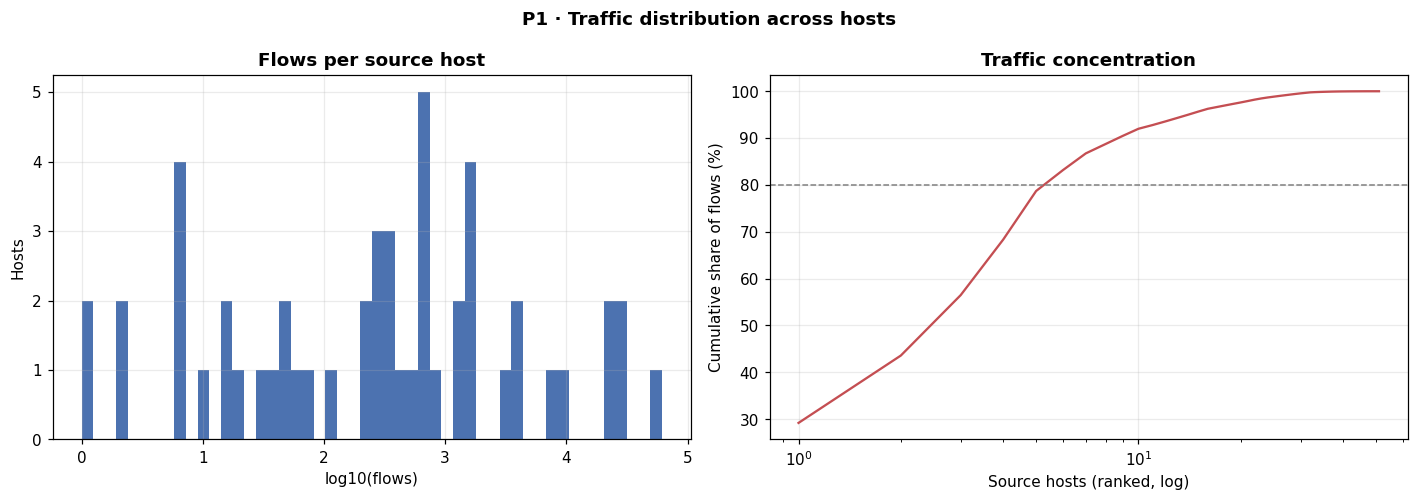


Reading: 776 hosts and 1,026 host pairs; 6 source hosts carry 80% of flows.


In [29]:
src_n, dst_n = df["src_ip"].nunique(), df["dst_ip"].nunique()
pairs_n = df.groupby(["src_ip", "dst_ip"]).size().shape[0]
P1 = pd.Series({"source hosts": src_n, "destination hosts": dst_n, "nodes (all hosts)": hosts,
                "distinct host pairs": pairs_n, "flows (edges)": len(df),
                "mean flows per pair": round(len(df) / pairs_n, 1),
                "density": round(pairs_n / (hosts * (hosts - 1)), 6)}).to_frame("value")
dump(P1, "P1_graph"); print(P1.to_string())

def is_private(ip):
    try: return ipaddress.ip_address(str(ip)).is_private
    except ValueError: return False
priv_src = df["src_ip"].map(is_private).mean()
priv_dst = df["dst_ip"].map(is_private).mean()
print(f"\nprivate source IPs: {priv_src*100:.1f}% of flows; private destination IPs: {priv_dst*100:.1f}%")

fps = df["src_ip"].value_counts()
cum = np.cumsum(fps.values) / len(df) * 100
n80 = int(np.argmax(cum >= 80) + 1)
FINDINGS.update(src_hosts=int(src_n), dst_hosts=int(dst_n), host_pairs=int(pairs_n),
                flows_per_pair=float(len(df) / pairs_n), src_hosts_80pct=n80,
                private_src_share=float(priv_src), private_dst_share=float(priv_dst))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hist(np.log10(fps.values), bins=50, color="#4C72B0")
axes[0].set_title("Flows per source host"); axes[0].set_xlabel("log10(flows)"); axes[0].set_ylabel("Hosts")
axes[1].plot(np.arange(1, len(cum) + 1), cum, color="#C44E52"); axes[1].set_xscale("log")
axes[1].axhline(80, ls="--", c="grey", lw=1)
axes[1].set_title("Traffic concentration"); axes[1].set_xlabel("Source hosts (ranked, log)")
axes[1].set_ylabel("Cumulative share of flows (%)")
fig.suptitle("P1 · Traffic distribution across hosts", fontweight="bold")
save(fig, "P1_host_distribution"); plt.show()
reading(f"{hosts:,} hosts and {pairs_n:,} host pairs; {n80} source hosts carry 80% of flows.")

## P2 · Identifier and timestamp leakage

If attacks come from a few machines, or happen in distinct time windows, then the
IP address or the timestamp alone reveals the label. We measure how much.

source hosts sending any attack : 19
100% attack hosts: 11, 100% normal: 32, mixed: 8
top 10 attacking IPs cover 100.0% of attack flows
src_ip
192.168.1.30     61585
192.168.1.31     30355
192.168.1.32     27227
192.168.1.193    23047
192.168.1.33      9439
192.168.1.37      7500
192.168.1.39       692
192.168.1.36       631
192.168.1.34       528
192.168.1.38        10


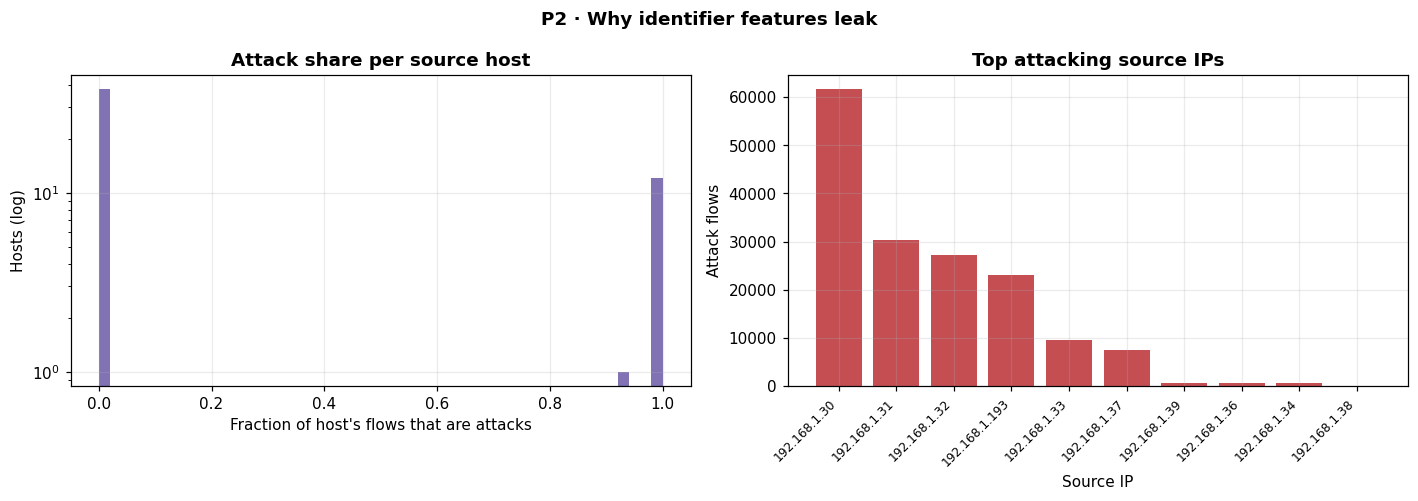

In [30]:
atk = df[df[TARGET_BIN] == 1]
purity = df.groupby("src_ip")[TARGET_BIN].mean()
top_atk = atk["src_ip"].value_counts().head(10)
share10 = top_atk.sum() / max(len(atk), 1) * 100
print(f"source hosts sending any attack : {atk['src_ip'].nunique():,}")
print(f"100% attack hosts: {(purity == 1).sum()}, 100% normal: {(purity == 0).sum()}, "
      f"mixed: {((purity > 0) & (purity < 1)).sum()}")
print(f"top 10 attacking IPs cover {share10:.1f}% of attack flows")
print(top_atk.to_string())
FINDINGS.update(attack_src_hosts=int(atk["src_ip"].nunique()), top10_attack_share=float(share10),
                pure_attack_hosts=int((purity == 1).sum()), pure_normal_hosts=int((purity == 0).sum()),
                mixed_hosts=int(((purity > 0) & (purity < 1)).sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hist(purity.values, bins=50, color="#8172B3"); axes[0].set_yscale("log")
axes[0].set_title("Attack share per source host"); axes[0].set_xlabel("Fraction of host's flows that are attacks")
axes[0].set_ylabel("Hosts (log)")
axes[1].bar(range(len(top_atk)), top_atk.values, color="#C44E52")
axes[1].set_xticks(range(len(top_atk))); axes[1].set_xticklabels(top_atk.index, rotation=45, ha="right", fontsize=8)
axes[1].set_title("Top attacking source IPs"); axes[1].set_xlabel("Source IP"); axes[1].set_ylabel("Attack flows")
fig.suptitle("P2 · Why identifier features leak", fontweight="bold")
save(fig, "P2_identifier_leakage"); plt.show()

In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

sub = np.random.RandomState(SEED).choice(len(df), min(100_000, len(df)), replace=False)
yb_s, ym_s = df[TARGET_BIN].iloc[sub].astype(int), df[TARGET_MULTI].iloc[sub]

def leak_score(cols, y):
    X = df[cols].iloc[sub].apply(lambda s: s.fillna(-1) if pd.api.types.is_numeric_dtype(s) else s.astype(str).astype("category").cat.codes)
    return cross_val_score(DecisionTreeClassifier(max_depth=14, random_state=SEED),
                           X, y, cv=3, scoring="f1_macro").mean()

LEAK = {}
LEAK["IPs only (binary)"] = leak_score(["src_ip", "dst_ip"], yb_s)
LEAK["IPs only (multiclass)"] = leak_score(["src_ip", "dst_ip"], ym_s)
if "ts" in df.columns:
    LEAK["timestamp only (binary)"] = leak_score(["ts"], yb_s)
    LEAK["timestamp only (multiclass)"] = leak_score(["ts"], ym_s)
for k, v in LEAK.items():
    print(f"macro-F1 using {k:<28}: {v:.4f}")
FINDINGS["leak_scores"] = {k: float(v) for k, v in LEAK.items()}
reading("A high score from identifiers or time alone means the model can memorise the "
        "testbed instead of learning attack behaviour. IPs and ts are therefore never "
        "model features; IPs only define graph nodes, and splits are made by host.")

macro-F1 using IPs only (binary)           : 0.9997
macro-F1 using IPs only (multiclass)       : 0.7847

Reading: A high score from identifiers or time alone means the model can memorise the testbed instead of learning attack behaviour. IPs and ts are therefore never model features; IPs only define graph nodes, and splits are made by host.


## P3 · Label-quality check

Raskovalov et al. (2022) reported two ToN-IoT labelling problems: normal exchanges
with the gateway/DNS resolver `192.168.1.1` labelled as attacks, and flows leaving
the test network labelled as attacks. We check how often each occurs here.

In [32]:
gw = "192.168.1.1"
touch_gw = (df["src_ip"] == gw) | (df["dst_ip"] == gw)
leaves = ~df["dst_ip"].map(is_private)

P3 = pd.DataFrame({
    "flows": [int(touch_gw.sum()), int(leaves.sum())],
    "labelled attack": [int((touch_gw & (df[TARGET_BIN] == 1)).sum()),
                        int((leaves & (df[TARGET_BIN] == 1)).sum())],
}, index=[f"involve gateway {gw}", "destination outside private ranges"])
P3["attack_%"] = (P3["labelled attack"] / P3["flows"].replace(0, np.nan) * 100).round(2)
dump(P3, "P3_label_quality"); print(P3.to_string())
print("\nAttack types among gateway flows:")
print(df.loc[touch_gw & (df[TARGET_BIN] == 1), TARGET_MULTI].value_counts().to_string())
FINDINGS["label_quality"] = P3.reset_index().values.tolist()
reading("Attack-labelled flows to the gateway or the open internet may be genuine attack "
        "traffic or labelling artefacts. We report them and, in Task 2, test results with "
        "and without these flows so a reader can judge their effect.")

                                    flows  labelled attack  attack_%
involve gateway 192.168.1.1         10941            10174     92.99
destination outside private ranges  32190            22611     70.24

Attack types among gateway flows:
type
ddos         5270
dos          1478
xss          1400
injection     705
scanning      576
mitm          568
password      177

Reading: Attack-labelled flows to the gateway or the open internet may be genuine attack traffic or labelling artefacts. We report them and, in Task 2, test results with and without these flows so a reader can judge their effect.


## P4 · Three-way host-disjoint split

Train / validation / test with **no source host in more than one part**, stratified
so every class appears in each part where possible. Then we compare a random split
with the host split for the same model and budget.

In [33]:
from sklearn.model_selection import StratifiedGroupKFold
groups = df["src_ip"].astype(str).values
y = df[TARGET_MULTI].values

def three_way(seed):
    sgk = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
    folds = [te for _, te in sgk.split(df, y, groups)]
    te_i, va_i = folds[0], folds[1]
    tr_i = np.setdiff1d(np.arange(len(df)), np.concatenate([te_i, va_i]))
    return tr_i, va_i, te_i

best = None
for s in range(10):                     # several seeds; keep the one covering most classes
    tr_i, va_i, te_i = three_way(s)
    cov = sum(len(set(y[p])) for p in (tr_i, va_i, te_i))
    if best is None or cov > best[0]:
        best = (cov, s, tr_i, va_i, te_i)
_, SPLIT_SEED, tr_i, va_i, te_i = best
parts = {"train": tr_i, "val": va_i, "test": te_i}

for k, v in parts.items():
    print(f"{k:<6}{len(v):>9,} flows ({len(v)/len(df)*100:5.1f}%) {pd.Series(groups[v]).nunique():>5} hosts")
sets = {k: set(groups[v]) for k, v in parts.items()}
overlap = {f"{a}-{b}": len(sets[a] & sets[b]) for a, b in [("train","val"),("train","test"),("val","test")]}
print("host overlap:", overlap)
assert all(v == 0 for v in overlap.values()), "HOST LEAK"

cov = pd.DataFrame({k: pd.Series(y[v]).value_counts() for k, v in parts.items()}).fillna(0).astype(int)
dump(cov, "P4_split_coverage"); print(cov.to_string())
missing = cov.index[(cov == 0).any(axis=1)].tolist()
print("classes missing from a part:", missing or "none")
FINDINGS.update(split_sizes={k: int(len(v)) for k, v in parts.items()},
                split_hosts={k: int(pd.Series(groups[v]).nunique()) for k, v in parts.items()},
                split_missing_classes=missing, split_seed=int(SPLIT_SEED))

train   144,684 flows ( 68.6%)    43 hosts
val       3,318 flows (  1.6%)     6 hosts
test     63,041 flows ( 29.9%)     2 hosts
host overlap: {'train-val': 0, 'train-test': 0, 'val-test': 0}
            train   val   test
backdoor    20000     0      0
ddos         3330     4  16666
dos          1314     0  18686
injection   12148     0   7852
mitm          519   524      0
normal      46385  2159   1456
password    10270     0   9730
ransomware  20000     0      0
scanning    11349     0   8651
xss         19369   631      0
classes missing from a part: ['backdoor', 'dos', 'injection', 'mitm', 'password', 'ransomware', 'scanning', 'xss']


In [34]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

sub = np.random.RandomState(SEED).choice(len(df), min(80_000, len(df)), replace=False)
Xq, gq = np.log1p(Xs.iloc[sub].clip(lower=0)).values, groups[sub]
res = {}
for name, yq in [("binary", df[TARGET_BIN].iloc[sub].astype(int).values),
                 ("multiclass", df[TARGET_MULTI].iloc[sub].values)]:
    a, b = train_test_split(np.arange(len(sub)), test_size=.3, random_state=SEED, stratify=yq)
    m = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=SEED,
                               class_weight="balanced").fit(Xq[a], yq[a])
    f_rand = f1_score(yq[b], m.predict(Xq[b]), average="macro")
    a, b = next(GroupShuffleSplit(1, test_size=.3, random_state=SEED).split(Xq, yq, gq))
    m = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=SEED,
                               class_weight="balanced").fit(Xq[a], yq[a])
    f_host = f1_score(yq[b], m.predict(Xq[b]), average="macro")
    res[name] = {"random": float(f_rand), "host": float(f_host)}
    print(f"{name:<11} random-split macro-F1 {f_rand:.4f} | host-split {f_host:.4f} | gap {f_rand-f_host:+.4f}")
FINDINGS["random_vs_host"] = res
reading("Same model, same features, same budget: the gap is the optimism a random split adds.")

binary      random-split macro-F1 0.9956 | host-split 0.9891 | gap +0.0066
multiclass  random-split macro-F1 0.9321 | host-split 0.3816 | gap +0.5505

Reading: Same model, same features, same budget: the gap is the optimism a random split adds.


## S · Findings summary

Everything measured above, exported to `findings.json` for the report.

In [35]:
def conv(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, dict): return {str(k): conv(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [conv(v) for v in o]
    return o
Path("findings.json").write_text(json.dumps(conv(FINDINGS), indent=2))
print(json.dumps(conv(FINDINGS), indent=2))
print("\nFigures:", sorted(p.name for p in OUT.glob("*.png")))
print("Tables :", sorted(p.name for p in TBL.glob("*.csv")))

{
  "rows": 211043,
  "columns": 44,
  "n_numeric": 17,
  "n_categorical": 20,
  "n_text": 1,
  "id_like": [
    "src_ip",
    "src_port",
    "dst_ip",
    "dst_port"
  ],
  "text_like": [
    "dns_query"
  ],
  "hosts": 776,
  "n_skewed": 16,
  "n_numeric_checked": 17,
  "most_skewed": "dst_ip_bytes",
  "max_skew": 444.671,
  "placeholder_cols": {
    "ssl_subject": 100.0,
    "ssl_issuer": 100.0,
    "http_orig_mime_types": 100.0,
    "weird_addl": 99.9,
    "http_resp_mime_types": 99.9,
    "http_uri": 99.9,
    "http_method": 99.9,
    "http_user_agent": 99.9,
    "http_version": 99.9,
    "http_trans_depth": 99.9
  },
  "dup_rows": 20569,
  "dup_feat_rows": 117317,
  "conflict_groups": 162,
  "conflict_rows": 22643,
  "near_constant": [
    "http_trans_depth",
    "http_version",
    "http_request_body_len",
    "http_response_body_len",
    "http_status_code",
    "weird_addl",
    "ssl_version",
    "ssl_cipher",
    "ssl_resumed",
    "ssl_established",
    "ssl_subject",
    

### Research question

> Does a host-topology graph improve macro-F1 over a top-K feature-similarity graph
> on TON_IoT, under the same three-way host-disjoint split and training budget?

Ngo et al. (2025) report that similarity graphs beat physical-link graphs on
NF-ToN-IoT; no study has tested that claim on hosts unseen during training.